# Getting Started

This tutorial is based on this `keras` tutorial: [keras Transfer Learning Guide](https://keras.io/guides/transfer_learning/).

We'll be creating a machine learning model using `keras` to classify images of cats and dogs.


First, import the necessary packages. You should also change your runtime to the GPU to speed it up.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "jax"
from keras import utils, datasets, models, layers
import tensorflow_datasets as tfds
import keras
from matplotlib import pyplot as plt
import numpy as np

Next, import the data.

In [2]:
train_ds, validation_ds, test_ds = tfds.load(
    "cats_vs_dogs",
    # 40% for training, 10% for validation, and 10% for test (the rest unused)
    split=["train[:40%]", "train[40%:50%]", "train[50%:60%]"],
    as_supervised=True,  # Include labels
)

print(f"Number of training samples: {train_ds.cardinality()}")
print(f"Number of validation samples: {validation_ds.cardinality()}")
print(f"Number of test samples: {test_ds.cardinality()}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...:   0%|          | 0/23262 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.QNV8VR_4.0.1/cats_vs_dogs-train.tfrecord*...:   0%…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Number of training samples: 9305
Number of validation samples: 2326
Number of test samples: 2326


Next, we'll resize the data so that all pictures are the same size. We'll also split into train, validation, and test datasets.

In [3]:
resize_fn = keras.layers.Resizing(150, 150)

train_ds = train_ds.map(lambda x, y: (resize_fn(x), y))
validation_ds = validation_ds.map(lambda x, y: (resize_fn(x), y))
test_ds = test_ds.map(lambda x, y: (resize_fn(x), y))

This next cell establishes an appropriate batch size so that the model loads data in a more efficient way.

In [4]:
from tensorflow import data as tf_data
batch_size = 64

train_ds = train_ds.batch(batch_size).prefetch(tf_data.AUTOTUNE).cache()
validation_ds = validation_ds.batch(batch_size).prefetch(tf_data.AUTOTUNE).cache()
test_ds = test_ds.batch(batch_size).prefetch(tf_data.AUTOTUNE).cache()

Let's take a look at some of the data. The function `show_sample()` will display three pictures of cats and three pictures of dogs from our dataset.

In [5]:
def show_sample():
  for images, labels in train_ds.take(1):
    plt.figure(figsize=(8,8))
    cats = [images[i] for i in range(64) if int(labels[i])==0]
    dogs = [images[i] for i in range(64) if int(labels[i])==1]
    for i in range(6):
      if i<3:
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(np.array(cats[i]).astype("int32"))
        plt.title('cat')
        plt.axis("off")
      else:
        ax = plt.subplot(2, 3, 1+i)
        plt.imshow(np.array(dogs[i]).astype("int32"))
        plt.title('dog')
        plt.axis("off")
    plt.tight_layout()

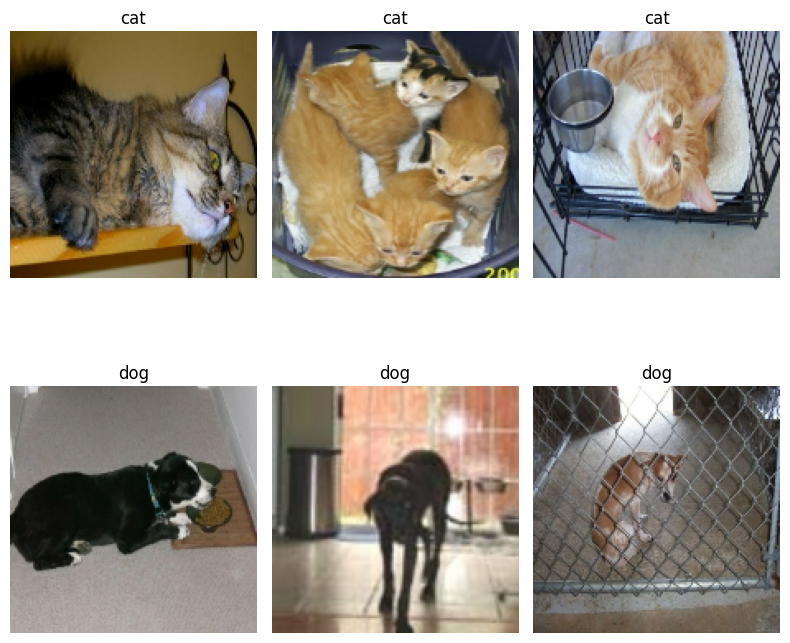

In [6]:
show_sample()

# Modeling

## Baseline
The baseline model is the simplest one: the one that always guesses the mode, or most common result. What would this be for our dataset and how accurate would it be? We'll compare our later models to the baseline -- they should all perform better than the baseline. The next cell creates a numpy iterator over the dataset so that we can access data points.

In [7]:
labels_iterator= train_ds.unbatch().map(lambda image, label: label).as_numpy_iterator()

In [8]:
l = list(labels_iterator)
print(l.count(0), l.count(1))

4637 4668


It looks like our dataset contains 4637 images of cats and 4668 images of dogs, so the baseline model would guess 'dog' every time and it would be correct only slightly more than half of the time.

## Model 1
This is our first model using `keras`. We'll use the `models.Sequential()` method to build it using the provided `layers` from `keras`. This model is a basic first guess -- I chose the layers somewhat arbitrarily.

In [9]:
model1 = models.Sequential([
    layers.Input((150, 150, 3)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.Dropout(0.2),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(2) # number of classes
])

In [10]:
model1.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model1.summary()

history = model1.fit(train_ds,
                    epochs=20,
                    validation_data=validation_ds)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 72, 72, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 73984)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       4,735,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,778,082 (18.23 MB)

 Trainable params: 4,778,082 (18.23 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 21s 105ms/step - accuracy: 0.5481 - loss: 23.7374 - val_accuracy: 0.6204 - val_loss: 0.6368
Epoch 2/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.6801 - loss: 0.5981 - val_accuracy: 0.6625 - val_loss: 0.6177
Epoch 3/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.7433 - loss: 0.5167 - val_accuracy: 0.6638 - val_loss: 0.6138
Epoch 4/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8037 - loss: 0.4210 - val_accuracy: 0.6531 - val_loss: 0.6810
Epoch 5/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8310 - loss: 0.3811 - val_accuracy: 0.6470 - val_loss: 0.7438
Epoch 6/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8543 - loss: 0.3336 - val_accuracy: 0.6311 - val_loss: 0.8283
Epoch 7/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8616 - loss: 0.3105 - val_accuracy: 0.6552 - val_loss: 0.7941
Epoch 8/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8863 - loss: 0.2815 - val_a

Now that we've compiled Model 1, we can take a look at the summary and accuracy. The summary tells us what each layer is doing -- take a look at each layer's inputs and outputs.



Let's write a quick function to visualize how the accuracy changes throughout the training process, which is 20 epochs.

In [11]:
def history_visualization(history):
  plt.plot(history.history["accuracy"], label = "training")
  plt.plot(history.history["val_accuracy"], label = "validation")
  plt.gca().set(xlabel = "epoch", ylabel = "accuracy")
  plt.legend()

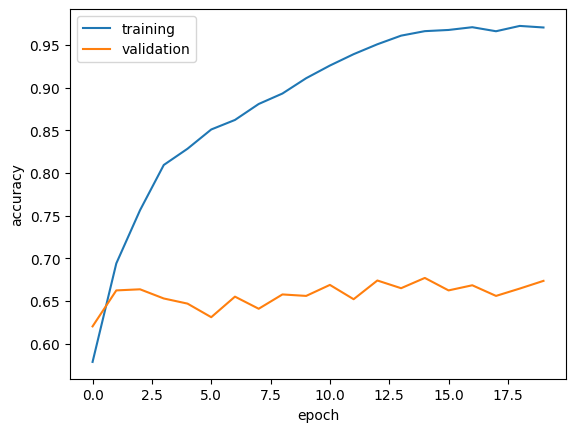

In [12]:
history_visualization(history)

**The accuracy of Model 1 stabilized around 60%-65% during training.** This is better than the baseline, but the model is not as accurate as we would like on the validation data, and it looks like there's been some issues with overfitting. We'll work on that in the next models.

## Model 2
In this model, we'll add in some image aumentation to reduce overfitting. This entails adding in the `RandomFlip` and `RandomRotation` layers provided by `keras`. The following function will be used to visualize what these layers do to a sample image.

In [13]:
def augmentation_visualization(image, f):
  plt.figure(figsize=(8,8), tight_layout=True)
  for i in range(6):
    ax = plt.subplot(2, 3, i + 1)
    augmented_image = f(np.expand_dims(image, 0))
    plt.imshow(np.array(augmented_image[0]).astype("int32"))
    plt.axis("off")

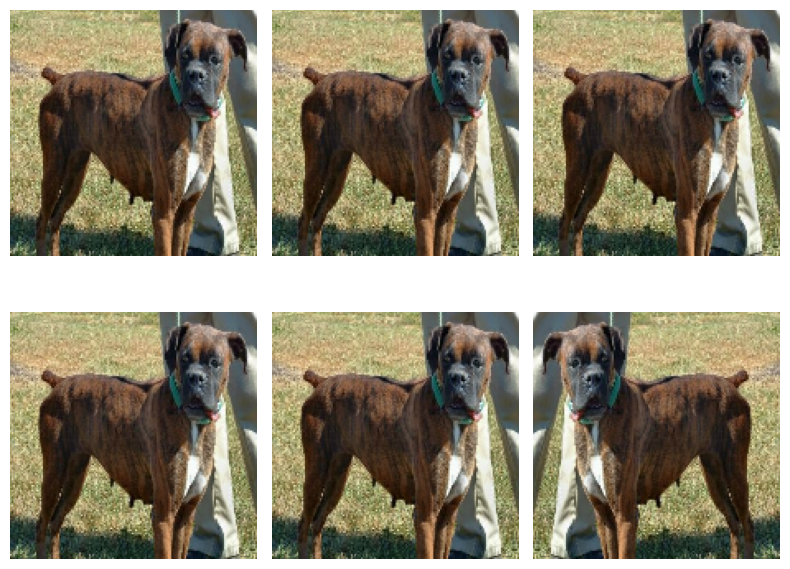

In [14]:
for images, labels in train_ds.take(1):
    image = images[0]
    augmentation_visualization(image, layers.RandomFlip("horizontal"))
    break

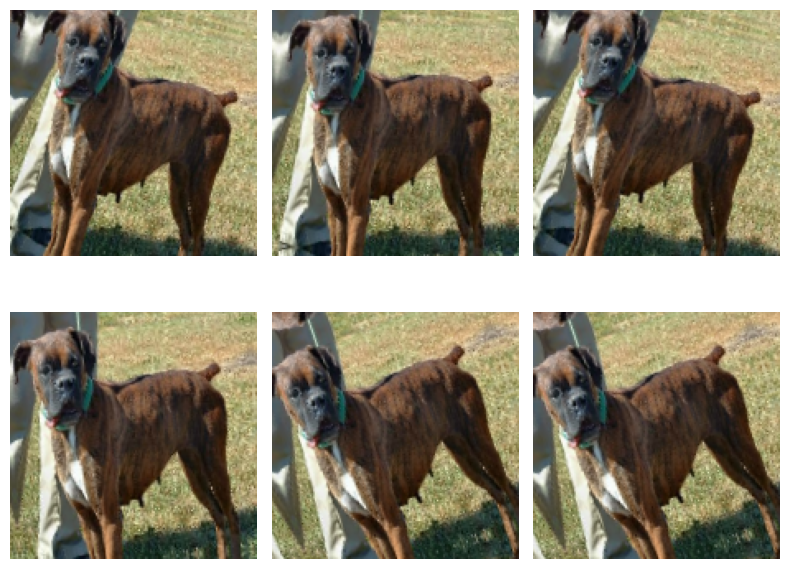

In [15]:
augmentation_visualization(image, layers.RandomRotation(0.1))

Adding the data augmentation layers to the beginning of Model 1 gives us Model 2:

In [16]:
model2 = models.Sequential([
    layers.Input((150, 150, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Dropout(0.2),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(2) # number of classes
])

In [17]:
model2.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model2.summary()

history = model2.fit(train_ds,
                    epochs=20,
                    validation_data=validation_ds)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)           │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_1 (RandomRotation)   │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 148, 148, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 74, 74, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 72, 72, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 72, 72, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 34, 34, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 73984)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │       4,735,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,814,978 (18.37 MB)

 Trainable params: 4,814,978 (18.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 50s 277ms/step - accuracy: 0.5527 - loss: 31.6835 - val_accuracy: 0.6113 - val_loss: 0.6594
Epoch 2/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 43s 292ms/step - accuracy: 0.5834 - loss: 0.6705 - val_accuracy: 0.5813 - val_loss: 0.6716
Epoch 3/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 30s 208ms/step - accuracy: 0.5749 - loss: 0.6738 - val_accuracy: 0.5464 - val_loss: 0.6869
Epoch 4/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 43s 292ms/step - accuracy: 0.5880 - loss: 0.6666 - val_accuracy: 0.5830 - val_loss: 0.6726
Epoch 5/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 42s 291ms/step - accuracy: 0.5882 - loss: 0.6687 - val_accuracy: 0.6225 - val_loss: 0.6462
Epoch 6/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 42s 291ms/step - accuracy: 0.6152 - loss: 0.6515 - val_accuracy: 0.5825 - val_loss: 0.6671
Epoch 7/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 44s 300ms/step - accuracy: 0.5795 - loss: 0.6696 - val_accuracy: 0.6217 - val_loss: 0.6440
Epoch 8/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 30s 205ms/step - accuracy: 0.6365 - loss: 

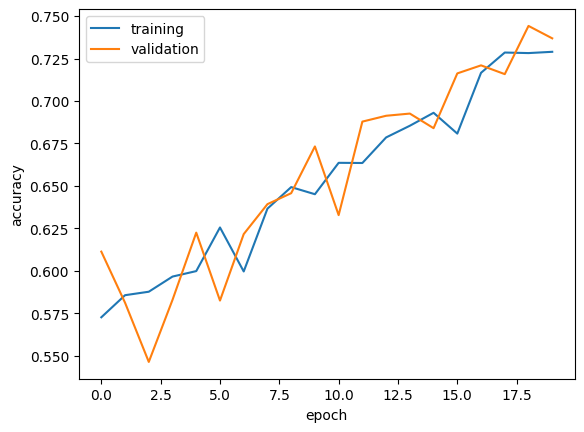

In [18]:
history_visualization(history)

**Model 2 stabilized around 70%-75%.** This is better than Model 1, and it seems to have improved on the overfitting issue.

## Model 3

Let's make things a bit easier for the model by preprocessing the data. We will create a `preprocessor` layer which will normalize the data so that the model will be able to focus on legitimate signal in the data rather than adjusting the weights to the data scale.

In [19]:
i = keras.Input(shape=(150, 150, 3))
# The pixel values have the range of (0, 255), but many models will work better if rescaled to (-1, 1.)
# outputs: `(inputs * scale) + offset`
scale_layer = keras.layers.Rescaling(scale=1 / 127.5, offset=-1)
x = scale_layer(i)
preprocessor = keras.Model(inputs = i, outputs = x)

`model3` is identical to `model2` but with the `preprocessor` layer added.

In [20]:
model3 = models.Sequential([
    preprocessor,
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Dropout(0.2),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(2) # number of classes
])

In [21]:
model3.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model3.summary()

history = model3.fit(train_ds,
                    epochs=20,
                    validation_data=validation_ds)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ functional_2 (Functional)            │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_flip_2 (RandomFlip)           │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_2 (RandomRotation)   │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 148, 148, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 74, 74, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 72, 72, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 72, 72, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 34, 34, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 73984)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │       4,735,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,814,978 (18.37 MB)

 Trainable params: 4,814,978 (18.37 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 43s 292ms/step - accuracy: 0.5563 - loss: 0.7026 - val_accuracy: 0.6505 - val_loss: 0.6115
Epoch 2/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 42s 291ms/step - accuracy: 0.6405 - loss: 0.6213 - val_accuracy: 0.7291 - val_loss: 0.5549
Epoch 3/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 32s 217ms/step - accuracy: 0.6961 - loss: 0.5731 - val_accuracy: 0.7580 - val_loss: 0.4957
Epoch 4/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 42s 291ms/step - accuracy: 0.7300 - loss: 0.5336 - val_accuracy: 0.7687 - val_loss: 0.4953
Epoch 5/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 31s 210ms/step - accuracy: 0.7487 - loss: 0.5089 - val_accuracy: 0.7713 - val_loss: 0.4665
Epoch 6/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 30s 207ms/step - accuracy: 0.7707 - loss: 0.4779 - val_accuracy: 0.7717 - val_loss: 0.4707
Epoch 7/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 42s 292ms/step - accuracy: 0.7809 - loss: 0.4673 - val_accuracy: 0.7954 - val_loss: 0.4395
Epoch 8/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 44s 300ms/step - accuracy: 0.7904 - loss: 0

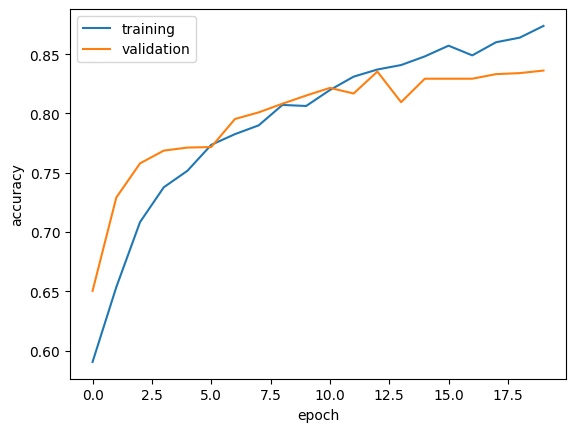

In [22]:
history_visualization(history)

**Model 3 stabilized around 80%-85% accuracy.** This is much better than Model 1 and Model 2, and it seems like there is not much overfitting, since the training and validation scores are very close.

## Model 4
For this model, we'll build on someone else's model that has already been made. The next block will import the model and create a layer that we can put into our model.

In [23]:
IMG_SHAPE = (150, 150, 3)
base_model = keras.applications.MobileNetV3Large(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               include_preprocessing=True,
                                               weights='imagenet')
base_model.trainable = False

i = keras.Input(shape=IMG_SHAPE)
x = base_model(i, training = False)
base_model_layer = keras.Model(inputs = i, outputs = x)

/usr/local/lib/python3.11/dist-packages/keras/src/applications/mobilenet_v3.py:517: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


We'll keep the data augmentation layers, but the preprocessing is taken care of by the `include_preprocessing` argument in `MobileNetV3Large`. Then I added one more `GlobalMaxPooling2D` layer, as well as the necessary final `Dense` layer of 2.

In [24]:
model4 = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    base_model_layer,
    layers.GlobalMaxPooling2D(),
    layers.Dense(2)
])

In [25]:
model4.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model4.summary()

history = model4.fit(train_ds,
                    epochs=20,
                    validation_data=validation_ds)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip_3 (RandomFlip)           │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_3 (RandomRotation)   │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ functional_4 (Functional)            │ (None, 5, 5, 960)           │       2,996,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling2d                 │ ?                           │               0 │
│ (GlobalMaxPooling2D)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,996,352 (11.43 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,996,352 (11.43 MB)

Epoch 1/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 80s 468ms/step - accuracy: 0.8898 - loss: 0.9460 - val_accuracy: 0.9656 - val_loss: 0.2487
Epoch 2/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 50s 341ms/step - accuracy: 0.9529 - loss: 0.3499 - val_accuracy: 0.9690 - val_loss: 0.2329
Epoch 3/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 90s 620ms/step - accuracy: 0.9561 - loss: 0.2840 - val_accuracy: 0.9708 - val_loss: 0.2102
Epoch 4/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 50s 342ms/step - accuracy: 0.9553 - loss: 0.2975 - val_accuracy: 0.9716 - val_loss: 0.2074
Epoch 5/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 52s 355ms/step - accuracy: 0.9561 - loss: 0.2675 - val_accuracy: 0.9721 - val_loss: 0.1809
Epoch 6/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 50s 340ms/step - accuracy: 0.9652 - loss: 0.1849 - val_accuracy: 0.9708 - val_loss: 0.1774
Epoch 7/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 93s 637ms/step - accuracy: 0.9539 - loss: 0.2703 - val_accuracy: 0.9742 - val_loss: 0.1744
Epoch 8/20
146/146 ━━━━━━━━━━━━━━━━━━━━ 50s 345ms/step - accuracy: 0.9661 - loss: 0

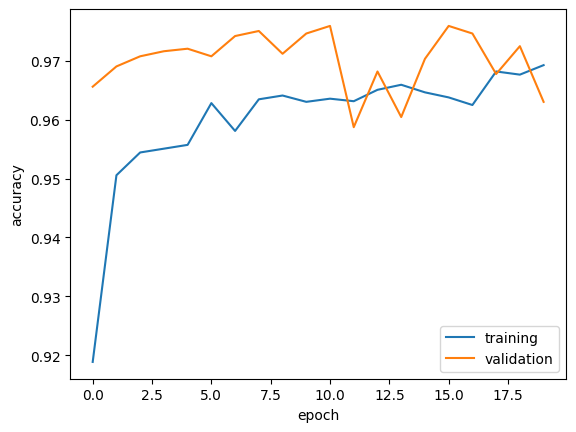

In [26]:
history_visualization(history)

**Model 4 stabilized around 96%-97% accuracy.** This is much better than our previous models. The validation score is around the same as the training score if not better, so the overfitting has been resolved.

## Testing on Unseen Data

In [27]:
model4.evaluate(test_ds)

37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 279ms/step - accuracy: 0.9627 - loss: 0.2169


[0.24329516291618347, 0.9613069891929626]

Model 4 was the best model, with a 96% accuracy score on the test dataset.